# 06 Baseline classifiers

## Loading libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, average_precision_score, roc_auc_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             precision_recall_curve)

os.makedirs("results/figures", exist_ok=True)
SEED = 42
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "savefig.dpi": 200})
pd.set_option("display.max_colwidth", 140)

FEAT_COLS = ["reasons_pct", "mentions_pct", "certainty", "negation_pct", "i_pct",
             "pos_emotion_clean_pct", "neg_emotion_clean_pct", "anger_clean_pct",
             "sadness_clean_pct", "money_clean_pct", "log_length"]
CLASS_NAMES = {1: "well-liked", 0: "disliked"}

df = pd.read_parquet("data/processed/features.parquet")
data = df[(df["rating"] <= 2) & (df["dissent_neg"] | df["agree_neg"])].copy()
data["y"] = data["dissent_neg"].astype(int)
data["log_length"] = np.log(data["n_words"].clip(lower=1))
data["text_clean"] = data["text_clean"].fillna("")
data = data.reset_index(drop=True)

print("scikit-learn version:", sklearn.__version__)
display(pd.DataFrame({"reviews": data["y"].value_counts(),
                      "share_%": (data["y"].value_counts(normalize=True) * 100).round(1)})
        .rename(index=CLASS_NAMES))

scikit-learn version: 1.6.1


,reviews,share_%
y,,
well-liked,16816,85.4
disliked,2881,14.6


## Train and test split

In [2]:
SPLIT_FILE = "data/processed/baseline_split.csv"
KEY = ["parent_asin", "user_id"]
if os.path.exists(SPLIT_FILE):
    data = data.drop(columns=["split"], errors="ignore").merge(pd.read_csv(SPLIT_FILE, dtype=str), on=KEY, how="left")
    print(SPLIT_FILE, "loaded (not overwritten)")
else:
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    _, test_idx = next(sgkf.split(data, data["y"], groups=data["parent_asin"]))
    data["split"] = "train"
    data.loc[test_idx, "split"] = "test"
    data[KEY + ["split"]].to_csv(SPLIT_FILE, index=False)
    print(SPLIT_FILE, "saved")

assert data["split"].notna().all(), "Some reviews have no split"
train, test = data[data["split"] == "train"].copy(), data[data["split"] == "test"].copy()
y_train, y_test = train["y"].to_numpy(), test["y"].to_numpy()

overlap = set(train["parent_asin"]) & set(test["parent_asin"])
same_text = set(train["text_clean"].str.strip().str.lower()) & set(test["text_clean"].str.strip().str.lower())
same_text.discard("")
assert len(overlap) == 0, "A product is in both train and test"

display(pd.DataFrame({"reviews": data.groupby("split").size(),
                      "products": data.groupby("split")["parent_asin"].nunique(),
                      "well_liked_%": (data.groupby("split")["y"].mean() * 100).round(1)}))
display(pd.DataFrame({"leakage check": ["Products in both sets", "Identical review texts in both sets"],
                      "count": [len(overlap), len(same_text)]}))

baseline_split.csv loaded (not overwritten)


,reviews,products,well_liked_%
split,,,
test,3741,1503,85.9
train,15956,6024,85.2


,leakage check,count
0,Products in both sets,0
1,Identical review texts in both sets,0


## Models and hyperparameter tuning

In [3]:
feature_part = Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
feature_part_nb = Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)), ("scale", MinMaxScaler())])
text_part = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True)

def logreg():
    return LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=2000)

def svm():
    return LinearSVC(class_weight="balanced", max_iter=5000)

def features_only(clf, fpart):
    return Pipeline([("prep", ColumnTransformer([("f", fpart, FEAT_COLS)])), ("clf", clf)])

def text_only(clf):
    return Pipeline([("prep", ColumnTransformer([("t", text_part, "text_clean")])), ("clf", clf)])

def text_and_features(clf, fpart):
    return Pipeline([("prep", ColumnTransformer([("t", text_part, "text_clean"), ("f", fpart, FEAT_COLS)])),
                     ("clf", clf)])

MODELS = {
    "Majority-class baseline": (Pipeline([("prep", ColumnTransformer([("f", "passthrough", ["log_length"])])),
                                          ("clf", DummyClassifier(strategy="most_frequent"))]), None),
    "Features + LR": (features_only(logreg(), feature_part), {"clf__C": [0.1, 1, 10]}),
    "Features + GB": (features_only(HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
                                    "passthrough"),
                      {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [3, None]}),
    "TF-IDF + NB": (text_only(ComplementNB()), {"clf__alpha": [0.1, 0.5, 1.0]}),
    "TF-IDF + SVM": (text_only(svm()), {"clf__C": [0.01, 0.1, 1]}),
    "TF-IDF + LR": (text_only(logreg()), {"clf__C": [0.1, 1, 10]}),
    "TF-IDF + features + NB": (text_and_features(ComplementNB(), feature_part_nb), {"clf__alpha": [0.1, 0.5, 1.0]}),
    "TF-IDF + features + SVM": (text_and_features(svm(), feature_part), {"clf__C": [0.01, 0.1, 1]}),
    "TF-IDF + features + LR": (text_and_features(logreg(), feature_part), {"clf__C": [0.1, 1, 10]}),
}

FITTED, tuning = {}, []
for name, (pipe, grid) in MODELS.items():
    if grid is None:
        FITTED[name] = pipe.fit(train, y_train)
        tuning.append({"model": name, "selected_hyperparameters": "-", "cv_macro_F1": np.nan})
        continue
    search = GridSearchCV(pipe, grid, scoring="f1_macro",
                          cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED), n_jobs=-1)
    search.fit(train, y_train, groups=train["parent_asin"])
    FITTED[name] = search.best_estimator_
    tuning.append({"model": name,
                   "selected_hyperparameters": ", ".join(f"{k.split('__')[-1]} = {v}" for k, v in search.best_params_.items()),
                   "cv_macro_F1": round(search.best_score_, 3)})
tuning = pd.DataFrame(tuning).set_index("model")
display(tuning)

vocab_size = len(FITTED["TF-IDF + LR"].named_steps["prep"].named_transformers_["t"].vocabulary_)
print("TF-IDF vocabulary size (single words and two-word phrases):", vocab_size)

,selected_hyperparameters,cv_macro_F1
model,,
Majority-class baseline,-,NaN
Features + LR,C = 10,0.497
Features + GB,"learning_rate = 0.05, max_depth = None",0.500
TF-IDF + NB,alpha = 0.1,0.649
TF-IDF + SVM,C = 0.1,0.648
TF-IDF + LR,C = 1,0.649
TF-IDF + features + NB,alpha = 0.1,0.649
TF-IDF + features + SVM,C = 0.1,0.648
TF-IDF + features + LR,C = 1,0.648


TF-IDF vocabulary size (single words and two-word phrases): 28956


## Test set results

In [4]:
def well_liked_score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, list(model.classes_).index(1)]
    s = model.decision_function(X)
    return (s - s.min()) / (s.max() - s.min())

def scores(y, pred, p):
    return {"accuracy": accuracy_score(y, pred),
            "macro_F1": f1_score(y, pred, average="macro"),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "PR_AUC_disliked": average_precision_score(1 - y, 1 - p),
            "ROC_AUC": roc_auc_score(y, p) if np.unique(p).size > 1 else 0.5}

rng = np.random.default_rng(SEED)
prod_codes = pd.factorize(test["parent_asin"])[0]
rows_by_prod = [np.flatnonzero(prod_codes == k) for k in range(prod_codes.max() + 1)]
boot_samples = [np.concatenate([rows_by_prod[k] for k in rng.integers(0, len(rows_by_prod), len(rows_by_prod))])
                for _ in range(1000)]

PRED, PROB, BOOT, rows = {}, {}, {}, []
for name, model in FITTED.items():
    PRED[name], PROB[name] = model.predict(test), well_liked_score(model, test)
    main = scores(y_test, PRED[name], PROB[name])
    BOOT[name] = pd.DataFrame([scores(y_test[i], PRED[name][i], PROB[name][i]) for i in boot_samples])
    row = {"model": name}
    for k, v in main.items():
        row[k] = v
        row[f"{k}_low"], row[f"{k}_high"] = BOOT[name][k].quantile([0.025, 0.975])
    rows.append(row)
res = pd.DataFrame(rows)
res.to_csv("results/baseline_results.csv", index=False)
pd.DataFrame({"y": y_test, **{f"pred | {n}": PRED[n] for n in FITTED}}).to_csv(
    "results/baseline_test_predictions.csv", index=False)

table = res[["model"]].copy()
table["accuracy"] = res["accuracy"].round(3)
for k in ["macro_F1", "balanced_accuracy", "PR_AUC_disliked", "ROC_AUC"]:
    table[k] = [f"{v:.3f} ({lo:.3f}–{hi:.3f})" for v, lo, hi in zip(res[k], res[f"{k}_low"], res[f"{k}_high"])]
display(table.set_index("model"))
print(f"Chance level for PR-AUC (disliked) = share of disliked-product reviews in the test set = {(1 - y_test).mean():.3f}")

,accuracy,macro_F1,balanced_accuracy,PR_AUC_disliked,ROC_AUC
model,,,,,
Majority-class baseline,0.859,0.462 (0.452–0.471),0.500 (0.500–0.500),0.141 (0.109–0.174),0.500 (0.500–0.500)
Features + LR,0.590,0.491 (0.467–0.516),0.564 (0.539–0.589),0.193 (0.151–0.248),0.594 (0.562–0.626)
Features + GB,0.643,0.515 (0.490–0.540),0.565 (0.539–0.592),0.196 (0.151–0.254),0.586 (0.553–0.621)
TF-IDF + NB,0.785,0.624 (0.581–0.664),0.651 (0.604–0.695),0.316 (0.231–0.414),0.720 (0.664–0.771)
TF-IDF + SVM,0.782,0.626 (0.586–0.664),0.658 (0.611–0.699),0.320 (0.235–0.416),0.722 (0.668–0.769)
TF-IDF + LR,0.781,0.625 (0.586–0.662),0.656 (0.609–0.697),0.321 (0.235–0.419),0.722 (0.668–0.769)
TF-IDF + features + NB,0.785,0.624 (0.582–0.663),0.651 (0.605–0.694),0.316 (0.230–0.413),0.720 (0.664–0.771)
TF-IDF + features + SVM,0.775,0.621 (0.583–0.657),0.656 (0.611–0.696),0.322 (0.234–0.420),0.721 (0.668–0.767)
TF-IDF + features + LR,0.774,0.620 (0.582–0.657),0.655 (0.609–0.696),0.322 (0.234–0.421),0.721 (0.667–0.768)


Chance level for PR-AUC (disliked) = share of disliked-product reviews in the test set = 0.141


## Paired bootstrap comparison

In [5]:
PAIRS = [("Features + LR", "Majority-class baseline"), ("Features + GB", "Features + LR"),
         ("TF-IDF + NB", "Features + LR"), ("TF-IDF + SVM", "Features + LR"), ("TF-IDF + LR", "Features + LR"),
         ("TF-IDF + LR", "TF-IDF + NB"), ("TF-IDF + LR", "TF-IDF + SVM"),
         ("TF-IDF + features + NB", "TF-IDF + NB"), ("TF-IDF + features + SVM", "TF-IDF + SVM"),
         ("TF-IDF + features + LR", "TF-IDF + LR")]
rows = []
for a, b in PAIRS:
    for metric in ["macro_F1", "PR_AUC_disliked"]:
        d = (BOOT[a][metric] - BOOT[b][metric]).to_numpy()
        rows.append({"comparison": f"{a} vs {b}", "metric": metric, "difference": d.mean(),
                     "ci_low": np.quantile(d, 0.025), "ci_high": np.quantile(d, 0.975)})
paired = pd.DataFrame(rows)
paired["real_difference"] = (paired["ci_low"] > 0) | (paired["ci_high"] < 0)
paired.to_csv("results/baseline_model_comparisons.csv", index=False)
display(paired.round(3).set_index(["comparison", "metric"]))

difference  ci_low  \
comparison                               metric                                
Features + LR vs Majority-class baseline macro_F1              0.029  -0.002   
                                         PR_AUC_disliked       0.055   0.030   
Features + GB vs Features + LR           macro_F1              0.024   0.010   
                                         PR_AUC_disliked       0.002  -0.014   
TF-IDF + NB vs Features + LR             macro_F1              0.132   0.097   
                                         PR_AUC_disliked       0.121   0.054   
TF-IDF + SVM vs Features + LR            macro_F1              0.134   0.100   
                                         PR_AUC_disliked       0.124   0.062   
TF-IDF + LR vs Features + LR             macro_F1              0.133   0.098   
                                         PR_AUC_disliked       0.126   0.064   
TF-IDF + LR vs TF-IDF + NB               macro_F1              0.001  -0.012   
                                         PR_AUC_disliked       0.005  -0.010   
TF-IDF + LR vs TF-IDF + SVM              macro_F1             -0.001  -0.005   
                                         PR_AUC_disliked       0.001  -0.001   
TF-IDF + features + NB vs TF-IDF + NB    macro_F1              0.000  -0.004   
                                         PR_AUC_disliked      -0.000  -0.002   
TF-IDF + features + SVM vs TF-IDF + SVM  macro_F1             -0.005  -0.012   
                                         PR_AUC_disliked       0.002  -0.003   
TF-IDF + features + LR vs TF-IDF + LR    macro_F1             -0.005  -0.011   
                                         PR_AUC_disliked       0.001  -0.004   

                                                          ci_high  \
comparison                               metric                     
Features + LR vs Majority-class baseline macro_F1           0.062   
                                         PR_AUC_disliked    0.082   
Features + GB vs Features + LR           macro_F1           0.038   
                                         PR_AUC_disliked    0.019   
TF-IDF + NB vs Features + LR             macro_F1           0.166   
                                         PR_AUC_disliked    0.193   
TF-IDF + SVM vs Features + LR            macro_F1           0.167   
                                         PR_AUC_disliked    0.191   
TF-IDF + LR vs Features + LR             macro_F1           0.164   
                                         PR_AUC_disliked    0.195   
TF-IDF + LR vs TF-IDF + NB               macro_F1           0.015   
                                         PR_AUC_disliked    0.022   
TF-IDF + LR vs TF-IDF + SVM              macro_F1           0.002   
                                         PR_AUC_disliked    0.005   
TF-IDF + features + NB vs TF-IDF + NB    macro_F1           0.006   
                                         PR_AUC_disliked    0.002   
TF-IDF + features + SVM vs TF-IDF + SVM  macro_F1           0.003   
                                         PR_AUC_disliked    0.008   
TF-IDF + features + LR vs TF-IDF + LR    macro_F1           0.002   
                                         PR_AUC_disliked    0.006   

                                                          real_difference  
comparison                               metric                            
Features + LR vs Majority-class baseline macro_F1                   False  
                                         PR_AUC_disliked             True  
Features + GB vs Features + LR           macro_F1                    True  
                                         PR_AUC_disliked            False  
TF-IDF + NB vs Features + LR             macro_F1                    True  
                                         PR_AUC_disliked             True  
TF-IDF + SVM vs Features + LR            macro_F1                    True  
                                         PR_AUC_disliked             True  
TF-IDF + LR vs Fea

## Stability across folds

In [6]:
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
             .split(data, data["y"], groups=data["parent_asin"]))
rows = []
for name, model in FITTED.items():
    for f, (tr, te) in enumerate(folds, start=1):
        m = clone(model).fit(data.iloc[tr], data["y"].iloc[tr])
        yt = data["y"].iloc[te].to_numpy()
        rows.append({"model": name, "fold": f, **scores(yt, m.predict(data.iloc[te]), well_liked_score(m, data.iloc[te]))})
stab = pd.DataFrame(rows)
stab.to_csv("results/baseline_fold_stability.csv", index=False)
display(stab.groupby("model", sort=False)[["macro_F1", "PR_AUC_disliked"]].agg(["mean", "std", "min", "max"]).round(3))

macro_F1                      PR_AUC_disliked         \
                            mean    std    min    max            mean    std   
model                                                                          
Majority-class baseline    0.460  0.003  0.455  0.464           0.147  0.011   
Features + LR              0.499  0.014  0.480  0.517           0.206  0.017   
Features + GB              0.507  0.019  0.483  0.534           0.206  0.018   
TF-IDF + NB                0.645  0.022  0.624  0.677           0.408  0.075   
TF-IDF + SVM               0.650  0.021  0.626  0.679           0.399  0.060   
TF-IDF + LR                0.649  0.022  0.625  0.680           0.401  0.061   
TF-IDF + features + NB     0.645  0.022  0.624  0.676           0.408  0.074   
TF-IDF + features + SVM    0.645  0.020  0.621  0.674           0.399  0.059   
TF-IDF + features + LR     0.645  0.021  0.620  0.674           0.400  0.060   

                                       
                           min    max  
model                                  
Majority-class baseline  0.135  0.164  
Features + LR            0.192  0.233  
Features + GB            0.192  0.238  
TF-IDF + NB              0.316  0.496  
TF-IDF + SVM             0.320  0.483  
TF-IDF + LR              0.321  0.486  
TF-IDF + features + NB   0.316  0.495  
TF-IDF + features + SVM  0.322  0.479  
TF-IDF + features + LR   0.322  0.482

## Per-class results and confusion matrices

In [7]:
per_class, cms = [], []
for name in list(FITTED)[1:]:
    rep = classification_report(y_test, PRED[name], labels=[0, 1], target_names=["disliked", "well-liked"],
                                output_dict=True, zero_division=0)
    for cls in ["disliked", "well-liked"]:
        per_class.append({"model": name, "class": cls, "precision": rep[cls]["precision"],
                          "recall": rep[cls]["recall"], "F1": rep[cls]["f1-score"], "support": int(rep[cls]["support"])})
    (tn, fp), (fn, tp) = confusion_matrix(y_test, PRED[name], labels=[0, 1])
    cms.append({"model": name, "disliked → disliked": tn, "disliked → well-liked": fp,
                "well-liked → disliked": fn, "well-liked → well-liked": tp})
display(pd.DataFrame(per_class).set_index(["model", "class"]).round(3))
display(pd.DataFrame(cms).set_index("model"))

precision  recall     F1  support
model                   class                                        
Features + LR           disliked        0.178   0.528  0.266      527
                        well-liked      0.886   0.600  0.716     3214
Features + GB           disliked        0.186   0.455  0.265      527
                        well-liked      0.883   0.674  0.765     3214
TF-IDF + NB             disliked        0.319   0.465  0.378      527
                        well-liked      0.905   0.837  0.870     3214
TF-IDF + SVM            disliked        0.319   0.486  0.385      527
                        well-liked      0.908   0.830  0.867     3214
TF-IDF + LR             disliked        0.318   0.482  0.383      527
                        well-liked      0.907   0.830  0.867     3214
TF-IDF + features + NB  disliked        0.319   0.465  0.379      527
                        well-liked      0.905   0.838  0.870     3214
TF-IDF + features + SVM disliked        0.310   0.490  0.380      527
                        well-liked      0.908   0.822  0.863     3214
TF-IDF + features + LR  disliked        0.309   0.488  0.378      527
                        well-liked      0.907   0.821  0.862     3214

,disliked → disliked,disliked → well-liked,well-liked → disliked,well-liked → well-liked
model,,,,
Features + LR,278,249,1285,1929
Features + GB,240,287,1047,2167
TF-IDF + NB,245,282,523,2691
TF-IDF + SVM,256,271,546,2668
TF-IDF + LR,254,273,546,2668
TF-IDF + features + NB,245,282,522,2692
TF-IDF + features + SVM,258,269,573,2641
TF-IDF + features + LR,257,270,574,2640


## Precision-recall curves

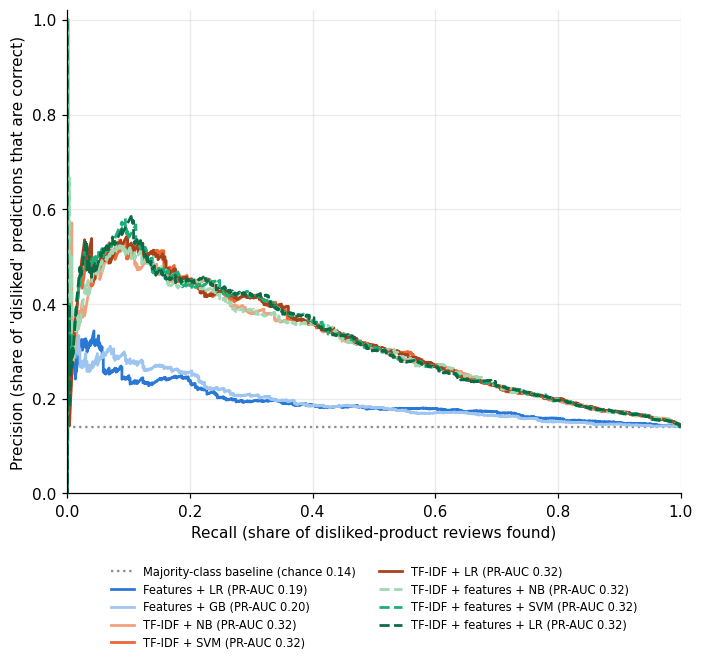

In [8]:
CURVES = {"Features + LR": ("#2a78d6", "-"), "Features + GB": ("#9ec5f0", "-"),
          "TF-IDF + NB": ("#f2a07b", "-"), "TF-IDF + SVM": ("#eb6834", "-"), "TF-IDF + LR": ("#a8401a", "-"),
          "TF-IDF + features + NB": ("#9fd8b3", "--"), "TF-IDF + features + SVM": ("#1baf7a", "--"),
          "TF-IDF + features + LR": ("#0b6b45", "--")}
fig, ax = plt.subplots(figsize=(6.5, 6.2))
ax.axhline((1 - y_test).mean(), color="#8e8e93", linewidth=1.5, linestyle=":",
           label=f"Majority-class baseline (chance {(1 - y_test).mean():.2f})")
for name, (colour, style) in CURVES.items():
    prec, rec, _ = precision_recall_curve(1 - y_test, 1 - PROB[name])
    ap = res.loc[res["model"] == name, "PR_AUC_disliked"].iloc[0]
    ax.plot(rec, prec, color=colour, linestyle=style, linewidth=1.8, label=f"{name} (PR-AUC {ap:.2f})")
ax.set_xlabel("Recall (share of disliked-product reviews found)")
ax.set_ylabel("Precision (share of 'disliked' predictions that are correct)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(fontsize=7.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
fig.savefig("results/figures/fig_baseline_pr_curves.png", bbox_inches="tight")
plt.show()

## Most influential words

In [9]:
lr = FITTED["TF-IDF + LR"]
vocab = lr.named_steps["prep"].named_transformers_["t"].get_feature_names_out()
coef = lr.named_steps["clf"].coef_[0]
order = np.argsort(coef)
top = pd.DataFrame({"towards_disliked": vocab[order[:25]], "weight_disliked": coef[order[:25]].round(3),
                    "towards_well_liked": vocab[order[::-1][:25]], "weight_well_liked": coef[order[::-1][:25]].round(3)})
top.index = range(1, 26)
top.to_csv("results/baseline_top_terms.csv", index=False)
display(top)

,towards_disliked,weight_disliked,towards_well_liked,weight_well_liked
1,screen,-4.993,oil,2.534
2,lashes,-3.020,smell,2.514
3,stencils,-2.896,but,2.400
4,protector,-2.798,scent,2.189
5,dried,-2.665,bottles,2.081
6,magnets,-2.652,bag,2.066
7,liner,-2.462,this,2.066
8,closure,-2.359,feet,1.998
9,mirror,-2.333,longer,1.983
10,blackheads,-2.300,dryer,1.927


## Error analysis

In [10]:
best = res.iloc[1:].sort_values("macro_F1", ascending=False)["model"].iloc[0]
errors = test[KEY + ["y", "text_clean"]].assign(p_well_liked=PROB[best], pred=PRED[best])
errors = errors[errors["y"] != errors["pred"]]
sample = pd.concat([errors[errors["y"] == g].sample(min(10, (errors["y"] == g).sum()), random_state=SEED) for g in [0, 1]])
sample["actual"] = sample["y"].map(CLASS_NAMES)
sample.to_csv("results/baseline_error_examples.csv", index=False)
print("Best model by macro-F1:", best, "| misclassified test reviews:", len(errors), "of", len(test))
display(sample[["actual", "p_well_liked", "text_clean"]].round(3).reset_index(drop=True))

Best model by macro-F1: TF-IDF + SVM | misclassified test reviews: 817 of 3741


,actual,p_well_liked,text_clean
0,disliked,0.564,I bought these with high hopes of not having to dig my fingers to the back of my mouth to remove my aligners. Those were false hopes unf...
1,disliked,0.605,"After a month, the spray quit spraying. This item is still full, but will not work so I'm not getting full usage with this defective can."
2,disliked,0.482,Don’t waste you’re money the second day my cap and the wand detached so I had to hot glue it back together worked for a bit I guess sinc...
3,disliked,0.561,Its pretty much an exposed half of a flat iron. the comb cover is useless and your beard WILL come into contact with the heated plate......
4,disliked,0.569,"I guess I didn’t know what over 11,000 beads should look like, but I sure think it’s more than what I received, especially compared to t..."
5,disliked,0.654,"Not happy with this.. These loofahs are tiny! They should be described as travel sized, or something similar to explain how small they a..."
6,disliked,0.661,The bottle I received did NOT glow in the dark. Was told it works best with neon colors. I did use a neon color and used on a regular ge...
7,disliked,0.538,"Do not know how many people have worked with this kind of material before (the plastic beads, and forming a tooth from it), BUT IF YOU H..."
8,disliked,0.485,We tried to use this with damp hair per instructions but it still did not seem to color my daughters hair green. Not sure if its bc she ...
9,disliked,0.593,"This is the second flosser I’ve had from this company that has stopped working after attempting to charge it. Additionally, the slightes..."


## Split check

In [11]:
display(pd.DataFrame({"check": ["Saved test set = stratified fold 1"],
                      "result": [set(data.index[data["split"] == "test"]) == set(folds[0][1])]}))

,check,result
0,Saved test set = stratified fold 1,True


## N-gram check

In [ ]:
NGRAM_RANGES = [(1, 1), (1, 2), (1, 3)]
NGRAM_MODELS = {"TF-IDF + NB": (ComplementNB(), {"clf__alpha": [0.1, 0.5, 1.0]}),
                "TF-IDF + SVM": (svm(), {"clf__C": [0.01, 0.1, 1]}),
                "TF-IDF + LR": (logreg(), {"clf__C": [0.1, 1, 10]})}

ngram_rows = []
for ngram_name, (ngram_clf, ngram_grid) in NGRAM_MODELS.items():
    ngram_pipe = Pipeline([("prep", ColumnTransformer([("t", TfidfVectorizer(min_df=5, max_df=0.9, sublinear_tf=True),
                                                         "text_clean")])), ("clf", ngram_clf)])
    ngram_search = GridSearchCV(ngram_pipe, {**ngram_grid, "prep__t__ngram_range": NGRAM_RANGES}, scoring="f1_macro",
                                cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED), n_jobs=1)
    ngram_search.fit(train, y_train, groups=train["parent_asin"])
    ngram_cv = pd.DataFrame(ngram_search.cv_results_)
    for ngram in NGRAM_RANGES:
        ngram_best = ngram_cv[ngram_cv["param_prep__t__ngram_range"].apply(tuple) == ngram] \
            .sort_values("mean_test_score").iloc[-1]
        ngram_rows.append({"model": ngram_name, "ngram_range": f"1–{ngram[1]} words",
                           "cv_macro_F1": ngram_best["mean_test_score"]})

ngram_table = pd.DataFrame(ngram_rows).pivot(index="model", columns="ngram_range", values="cv_macro_F1")
ngram_table["gain from three-word phrases"] = ngram_table["1–3 words"] - ngram_table["1–2 words"]
display(ngram_table.round(3))